# Extracción con evidencia: fuente, contradicción y conciliación

## Lectura de los resultados ejecutados

Sumar transferencias al salario sobreestimó el ingreso en 2.450.000 COP por caso en promedio en este corpus. Los cinco casos de mutación literal retuvieron solo el original; un span semánticamente mal etiquetado sí pasó.

Resultados académicos adicionales (valores del experimento):

```json
{
  "evidence_claim_metrics": [
    {
      "method": "span",
      "TP": 50,
      "FP": 100,
      "FN": 0,
      "precision": 0.3333333333333333,
      "recall": 1.0
    },
    {
      "method": "lexical",
      "TP": 50,
      "FP": 0,
      "FN": 0,
      "precision": 1.0,
      "recall": 1.0
    }
  ],
  "paraphrase_failure_retained": true
}
```

Datos sintéticos. Esta sección acompaña las salidas guardadas y no es una medición comercial o bancaria.

## Resumen y alcance

Laboratorio de arquitectura con datos sintéticos y sin API comercial. Se ejecutan contratos neutrales y escenarios de error. Las métricas resultantes describen exclusivamente este generador; no son benchmarks de Jev ni ScaleDown.

## Contexto y métodos

Se comparan políticas sobre las mismas realizaciones. Semilla 20261023; calibración y test independientes. El objetivo es entender qué capa detecta cada fallo y dónde la abstención preserva incertidumbre.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize':(8,4.6),'font.size':11,'axes.spines.top':False,
                     'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18})
BLUE='#245B83'; GOLD='#B57A21'; GRAY='#4D5358'
rng_depth=np.random.default_rng(20261023)

In [2]:
from pathlib import Path
import sys
sys.path.insert(0,str(Path.cwd().parent))
from src.contracts import Decision, Evidence, choose_action, select_threshold, extract_literal

### Evidencia literal y semántica

$$v=s[a:b],\quad h=SHA256(UTF8(s)).$$

La igualdad del span prueba procedencia literal sobre este snapshot; no acredita que sea ingreso ni que el documento sea auténtico. Los offsets se expresan en puntos de código Unicode, no bytes.

### Corpus de documentos y verdad de referencia

Cada caso incluye ingreso declarado, transferencia y corrección. El dataset es completamente sintético y explícito.

In [3]:
import hashlib
from dataclasses import replace
records=[]
for i in range(200):
    salary=int(rng_depth.integers(1,9))*1000000
    transfer=int(rng_depth.integers(1,5))*1000000
    text=f'Expediente {i}. Salario mensual: {salary} COP. Transferencia interna: {transfer} COP. No sumar la transferencia al ingreso. Café.'
    records.append({'id':i,'source':text,'salary':salary,'transfer':transfer})
display(pd.DataFrame(records)[['id','salary','transfer']].head())

,id,salary,transfer
0,0,5000000,2000000
1,1,4000000,3000000
2,2,7000000,4000000
3,3,7000000,2000000
4,4,8000000,4000000


### Extracción con spans y ambigüedad

El doble de prueba encuentra solo valores únicos. Una repetición requiere desambiguar por contexto en lugar de escoger la primera coincidencia.

In [4]:
receipts=[]
for record in records:
    literal=str(record['salary'])
    evidence=extract_literal(record['source'],literal)
    receipts.append({'id':record['id'],'evidence':evidence,'verified':bool(evidence and evidence.verify(record['source']))})
print({'casos':len(records),'evidencias_verificadas':sum(r['verified'] for r in receipts),'abstenciones':sum(r['evidence'] is None for r in receipts)})
assert extract_literal('100 y 100','100') is None

{'casos': 200, 'evidencias_verificadas': 171, 'abstenciones': 29}


### Cambios de fuente, offsets y Unicode

El hash exige texto inmutable. Normalizar acentos o espacios crea una nueva versión y requiere recalcular offsets.

In [5]:
source='Café: salario 3000000 COP.'
evidence=extract_literal(source,'3000000')
assert evidence.verify(source)
assert not evidence.verify(source+' ')
assert not replace(evidence,start=evidence.start+1).verify(source)
assert evidence.start!=len(source[:evidence.start].encode('utf-8'))
print({'offset_unicode':evidence.start,'offset_bytes':len(source[:evidence.start].encode('utf-8')),'hash':evidence.document_hash[:16]})

{'offset_unicode': 14, 'offset_bytes': 15, 'hash': 'fbc07f9429e81389'}


### Matriz de fallos de contrato

No se reporta tasa de seguridad: son cinco mutaciones dirigidas y reproducibles, no ataques muestreados de población.

In [6]:
mutations=[('original',evidence,source),('fuente alterada',evidence,source+' '),
           ('valor inventado',replace(evidence,value='999'),source),('offset incorrecto',replace(evidence,end=evidence.end-1),source),
           ('hash incorrecto',replace(evidence,document_hash='0'*64),source)]
mutation_table=pd.DataFrame([{'caso':name,'aceptado':e.verify(s)} for name,e,s in mutations]);display(mutation_table)
assert mutation_table.aceptado.sum()==1

,caso,aceptado
0,original,True
1,fuente alterada,False
2,valor inventado,False
3,offset incorrecto,False
4,hash incorrecto,False


### Conciliación del ingreso

$$I_m=\sum_e monto_e\,f_e\,1[e\text{ es ingreso externo único}].$$

Se conserva período y concepto. En este corpus el salario es mensual y las transferencias son internas; la suma indiscriminada sobreestima el ingreso. No se infiere capacidad de pago o solvencia solo por el documento.

### Suma de movimientos frente a ingreso

La misma cifra puede tener fuente verificable y pertenecer al concepto equivocado.

{'sobreestimacion_media_COP': 2450000.0, 'ratio_mediano': 1.5}


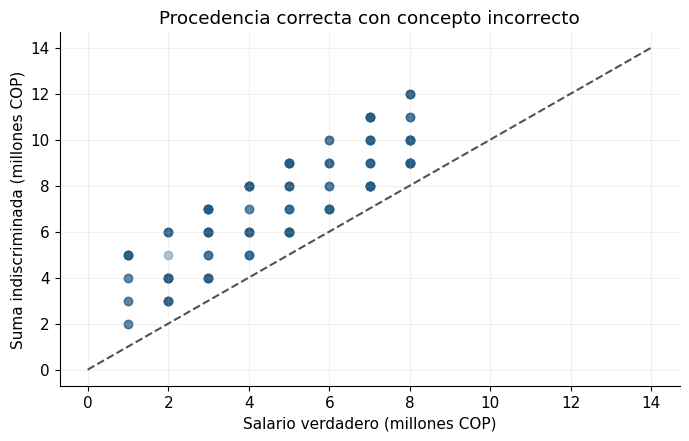

In [7]:
salary=np.array([x['salary'] for x in records]);transfer=np.array([x['transfer'] for x in records])
naive=salary+transfer
semantic_error=transfer # flujo real, concepto incorrecto
assert np.all(naive>=salary)
print({'sobreestimacion_media_COP':float(np.mean(naive-salary)), 'ratio_mediano':float(np.median(naive/salary))})
fig,ax=plt.subplots();ax.scatter(salary/1e6,naive/1e6,alpha=.35,color=BLUE);ax.plot([0,14],[0,14],ls='--',color=GRAY)
ax.set(xlabel='Salario verdadero (millones COP)',ylabel='Suma indiscriminada (millones COP)',title='Procedencia correcta con concepto incorrecto');plt.show()

### Normalización de periodicidad

Las conversiones son convenciones explícitas. Quincenal (24 pagos/año) difiere de cada 14 días (365.25/14 pagos/año).

In [8]:
factors={'mensual':1.,'anual':1/12,'semanal':365.25/7/12,'quincenal':2.,'cada_14_dias':365.25/14/12}
periods=pd.DataFrame({'periodo':list(factors),'factor_mensual':list(factors.values())})
periods['monto_literal_COP']=1500000
periods['equivalente_mensual_COP']=periods.factor_mensual*periods.monto_literal_COP
display(periods.round(2))
assert factors['quincenal']!=factors['cada_14_dias']

,periodo,factor_mensual,monto_literal_COP,equivalente_mensual_COP
0,mensual,1.00,1500000,1500000.00
1,anual,0.08,1500000,125000.00
2,semanal,4.35,1500000,6522321.43
3,quincenal,2.00,1500000,3000000.00
4,cada_14_dias,2.17,1500000,3261160.71


### Compresión antes de extraer

Se evalúa una ablación deliberadamente simple: conservar el prefijo elimina correcciones al final. No es una implementación de ScaleDown Compress.

,limite_caracteres,retencion_evidencia,longitud_media
0,40,0.0,40.0
1,100,0.0,100.0
2,200,0.0,200.0
3,400,1.0,326.0
4,800,1.0,326.0


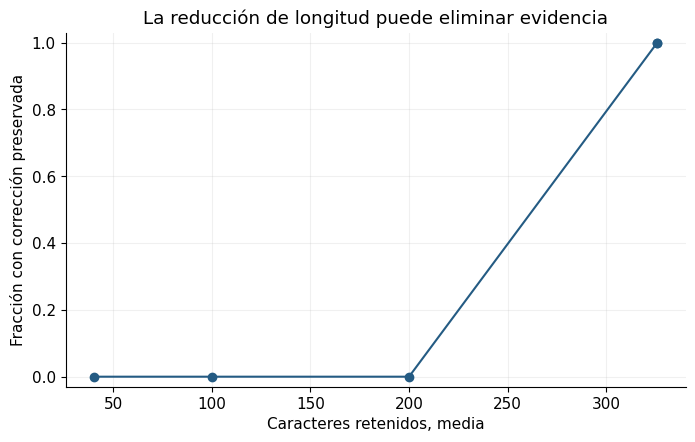

In [9]:
docs=[]
for i in range(100):
    original=2000000+i*1000
    correction=original+500000
    text=f'Ingreso reportado {original} COP. '+'Contexto administrativo. '*10+f'Corrección final: ingreso válido {correction} COP.'
    docs.append((text,str(correction)))
retention=[]
for chars in [40,100,200,400,800]:
    retained=np.mean([truth in text[:chars] for text,truth in docs])
    retention.append({'limite_caracteres':chars,'retencion_evidencia':retained,'longitud_media':np.mean([len(t[:chars]) for t,_ in docs])})
retention=pd.DataFrame(retention);display(retention)
fig,ax=plt.subplots();ax.plot(retention.longitud_media,retention.retencion_evidencia,'o-',color=BLUE)
ax.set(ylim=(-.03,1.03),xlabel='Caracteres retenidos, media',ylabel='Fracción con corrección preservada',title='La reducción de longitud puede eliminar evidencia');plt.show()

### Span válido con etiqueta errónea

Se construye un campo salario que apunta a una transferencia real. El contrato literal pasa; la regla semántica debe detectarlo.

In [10]:
text='Salario: 3000000 COP. Transferencia: 9000000 COP.'
wrong=extract_literal(text,'9000000')
assert wrong.verify(text)
semantic_label='salario'
correct_label='transferencia'
assert semantic_label!=correct_label
print('Procedencia literal: válida; etiqueta de concepto: incorrecta.')

Procedencia literal: válida; etiqueta de concepto: incorrecta.


### Desconocidos y revisión

Calcular una señal solo cuando existen campos suficientes. No convertir None en cero.

In [11]:
fields=[{'salary':3000000,'period':'mensual'}, {'salary':None,'period':'mensual'}, {'salary':3000000,'period':None}]
def normalize_or_review(field):
    if field['salary'] is None or field['period'] not in factors:return {'status':'review','income':None}
    return {'status':'ready','income':field['salary']*factors[field['period']]}
decisions=[normalize_or_review(x) for x in fields];display(pd.DataFrame(decisions))
assert decisions[1]['income'] is None and decisions[2]['income'] is None

,status,income
0,ready,3000000.0
1,review,NaN
2,review,NaN


### Costo de revisión y pérdida por automatizar

Superficie de escenario: no se estima causalmente el costo ni la eficacia de la revisión.

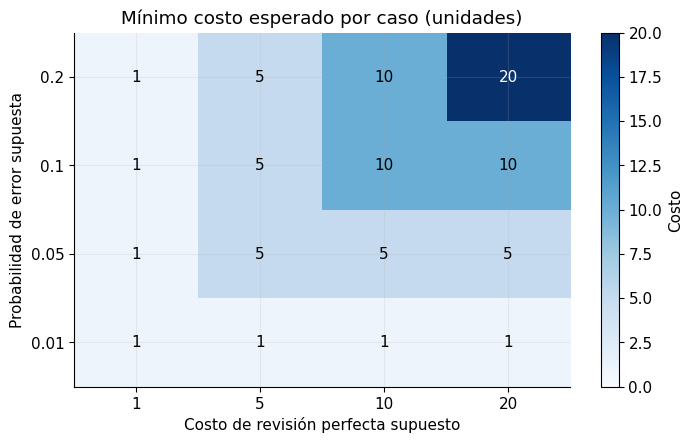

In [12]:
error_rates=np.array([.01,.05,.1,.2]);review_costs=np.array([1,5,10,20])
loss_per_error=100.
expected_auto=error_rates*loss_per_error
cost_matrix=np.minimum(expected_auto[:,None],review_costs[None,:])
fig,ax=plt.subplots();im=ax.imshow(cost_matrix,origin='lower',aspect='auto',cmap='Blues',vmin=0,vmax=20)
ax.set_xticks(range(4),review_costs);ax.set_yticks(range(4),error_rates)
for i in range(4):
    for j in range(4):ax.text(j,i,f'{cost_matrix[i,j]:.0f}',ha='center',va='center',color='white' if cost_matrix[i,j]>12 else 'black')
ax.set(xlabel='Costo de revisión perfecta supuesto',ylabel='Probabilidad de error supuesta',title='Mínimo costo esperado por caso (unidades)');fig.colorbar(im,ax=ax,label='Costo');plt.show()

## Hallazgos y uso

La validación literal detecta cambios de documento y spans inventados, pero el contraejemplo semántico pasa. La compresión por prefijo pierde correcciones y las transferencias inflan ingreso al sumarlas. Estos resultados justifican conservar fuente, separar concepto y mantener revisión; no acreditan un extractor comercial o un motor crediticio.

### Duplicados de eventos y datos conflictivos

La clave de evento evita sumar dos veces, pero un duplicado con valores distintos requiere revisión y no se elimina silenciosamente.

In [13]:
ledger=[{'event':'a','amount':3000000,'kind':'salary'},{'event':'a','amount':3000000,'kind':'salary'},
        {'event':'b','amount':2000000,'kind':'internal'}]
unique={}
for event in ledger:
    key=event['event']
    if key in unique and unique[key]!=event:raise ValueError('duplicado conflictivo')
    unique[key]=event
income=sum(e['amount'] for e in unique.values() if e['kind']=='salary')
assert income==3000000
assert sum(e['amount'] for e in ledger)==8000000
print({'suma_sin_conciliar':8000000,'ingreso_unico_externo':income})

{'suma_sin_conciliar': 8000000, 'ingreso_unico_externo': 3000000}


### Disponibilidad de documentos

Un hecho con fecha anterior pero recibido después no puede informar una decisión pasada.

In [14]:
from datetime import date
application=date(2026,10,23)
events=[{'event_date':date(2026,10,1),'available':date(2026,10,22),'amount':3000000},
        {'event_date':date(2026,10,2),'available':date(2026,10,24),'amount':9000000}]
known=[e for e in events if e['event_date']<=application and e['available']<=application]
assert len(known)==1
print({'ingreso_disponible':sum(e['amount'] for e in known),'suma_retrospectiva_con_fuga':sum(e['amount'] for e in events)})

{'ingreso_disponible': 3000000, 'suma_retrospectiva_con_fuga': 12000000}


### OCR y normalización: preservar ambas versiones

Cambiar O por 0 puede reparar un monto o alterar un identificador. Una normalización no es universal y no conserva el hash original.

In [15]:
raw='Monto: 3OOO000 COP; referencia: ABCO1.'
normalized=raw.replace('O','0')
assert hashlib.sha256(raw.encode()).hexdigest()!=hashlib.sha256(normalized.encode()).hexdigest()
print({'raw':raw,'normalizado_global':normalized,'referencia_alterada':'ABC01' in normalized})
# La versión corregida necesita su propio mapa al original; no reutilizar offsets sin validación.
print('Revisión requerida para resolver el campo y conservar procedencia.')

{'raw': 'Monto: 3OOO000 COP; referencia: ABCO1.', 'normalizado_global': 'Monto: 3000000 C0P; referencia: ABC01.', 'referencia_alterada': True}
Revisión requerida para resolver el campo y conservar procedencia.


### Matriz de evaluación semántica

Procedencia y concepto son ejes separados. El ejemplo contiene casos válidos, incorrectos y abstenciones; no es exactitud de un proveedor.

In [16]:
examples=pd.DataFrame([
 {'span_verificado':True,'concepto_correcto':True,'estado':'automatable'},
 {'span_verificado':True,'concepto_correcto':False,'estado':'error_semantico'},
 {'span_verificado':False,'concepto_correcto':True,'estado':'fuente_no_verificada'},
 {'span_verificado':False,'concepto_correcto':False,'estado':'review'}])
display(examples)
assert not (examples.span_verificado==examples.concepto_correcto).all()

,span_verificado,concepto_correcto,estado
0,True,True,automatable
1,True,False,error_semantico
2,False,True,fuente_no_verificada
3,False,False,review


### Interpretación de las pruebas adicionales

Cada experimento modifica un supuesto concreto. Las comparaciones conservan denominadores, unidades y desconocidos; los resultados negativos forman parte de la evidencia. Las simulaciones no convierten un diseño en un sistema operativo ni sustituyen validación independiente con datos aprobados.

## Próximos experimentos

Comparar proveedores sobre corpus etiquetado y snapshots iguales; registrar versión y latencia medida. Añadir OCR real aprobado, idioma, distribución temporal y revisores falibles. Diseñar pruebas de integración antes de conectar efectos externos.

Fuentes y contrato de arquitectura: [README principal](../README.md).

## Ampliación académica: literatura, fórmulas y experimento

Consulta bibliográfica del 23 de octubre de 2026. Se distingue método publicado, derivación propia y experimento sintético. El [mapa bibliográfico](https://github.com/Jose85100/Portafolio/blob/research/2026-10-23-multi-domain-cycle/reviews/2026-10-23-academic/README.md) en la raíz del repositorio registra publicaciones, acceso y brechas; las fuentes específicas se enlazan debajo.

### Procedencia literal y fidelidad semántica se evalúan por separado

[Maynez et al., ACL 2020](https://doi.org/10.18653/v1/2020.acl-main.173) estudia inconsistencias respecto de la fuente y evaluación de fidelidad en resúmenes. Aquí proponemos un test de contrato propio, sin reproducir su modelo de entailment ni usar XSum.

$$P_{soporte}=TP/(TP+FP),\quad R_{soporte}=TP/(TP+FN).$$

La etiqueta indica si la afirmación de ingreso está respaldada por este documento, no si es verdadera en el mundo. Las abstenciones se conservan; copiar una cifra real bajo el concepto equivocado puede pasar el hash.

### Corpus adversarial con etiquetas explícitas

Cuatro clases sintéticas: campo respaldado, concepto incorrecto, valor inventado y cifra negada. Un verificador lexical es deliberadamente limitado.

In [17]:
import re
paper_rng=np.random.default_rng(2307)
claim_rows=[]
for i in range(50):
    amount=int(paper_rng.integers(1,8))*1000000
    examples=[
        (f'Salario: {amount} COP.',str(amount),True,'respaldado'),
        (f'Transferencia: {amount} COP.',str(amount),False,'concepto'),
        (f'Salario: {amount} COP.',str(amount+12345),False,'inventado'),
        (f'No recibe salario: {amount} COP.',str(amount),False,'negado')]
    for source,literal,supported,kind in examples:
        ev=extract_literal(source,literal)
        span_ok=bool(ev and ev.verify(source))
        lexical=bool(span_ok and re.search(r'Salario: '+re.escape(literal)+r' COP',source))
        claim_rows.append({'kind':kind,'truth':supported,'span':span_ok,'lexical':lexical})
claims=pd.DataFrame(claim_rows)

### Precisión, recall y fallo de paráfrasis

El verificador lexical puede ganar en la plantilla y perder al cambiar la redacción. Se incluye ese contraejemplo para evitar vender la regla como NLI.

ACADEMIC_METRICS:{"evidence_claim_metrics": [{"method": "span", "TP": 50, "FP": 100, "FN": 0, "precision": 0.3333333333333333, "recall": 1.0}, {"method": "lexical", "TP": 50, "FP": 0, "FN": 0, "precision": 1.0, "recall": 1.0}], "paraphrase_failure_retained": true}


,method,TP,FP,FN,precision,recall
0,span,50,100,0,0.333333,1.0
1,lexical,50,0,0,1.000000,1.0


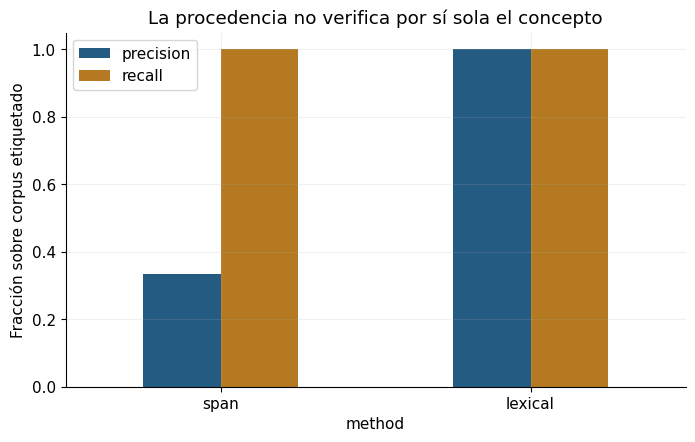

In [18]:
verification_rows=[]
for name in ['span','lexical']:
    predicted=claims[name].to_numpy();truth=claims.truth.to_numpy()
    tp=int(np.sum(predicted & truth));fp=int(np.sum(predicted & ~truth));fn=int(np.sum(~predicted & truth))
    verification_rows.append({'method':name,'TP':tp,'FP':fp,'FN':fn,'precision':tp/max(tp+fp,1),'recall':tp/max(tp+fn,1)})
verification=pd.DataFrame(verification_rows);display(verification)
paraphrase='Retribución laboral mensual: 3000000 COP.'
assert extract_literal(paraphrase,'3000000').verify(paraphrase)
assert not re.search(r'Salario: 3000000 COP',paraphrase)
fig,ax=plt.subplots()
verification.set_index('method')[['precision','recall']].plot.bar(ax=ax,color=[BLUE,GOLD],rot=0)
ax.set(ylim=(0,1.05),ylabel='Fracción sobre corpus etiquetado',title='La procedencia no verifica por sí sola el concepto')
plt.show()
import json
print('ACADEMIC_METRICS:'+json.dumps({'evidence_claim_metrics':verification_rows,'paraphrase_failure_retained':True}))

### Ideas y cierre pendiente

Crear anotaciones humanas de concepto, negación, moneda, período y correcciones; medir acuerdo entre anotadores; comparar reglas con NLI y revisión humana bajo el mismo presupuesto. Añadir recuperación y OCR reales aprobados. La exactitud en plantillas no constituye generalización documental.